# Task 3: Car Price Prediction with Machine Learning

**Goal:** Car ki features (present price, kms, age, fuel, brand, etc.) se uski *selling price* predict karna (regression).

> Note: Dataset mein `Selling_Price` aur `Present_Price` **lakh rupees** mein hain.

## Step 1: Libraries aur Data load karna

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

df = pd.read_csv("car_data.csv")
print(df.shape)
df.head()

(301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## Step 2: Data ko samajhna (Exploration)
Dekhte hain columns, data types, missing values aur duplicates.

In [2]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB

Missing values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Duplicate rows: 2


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.00,301.00,301.00,301.00,301.00
mean,2013.63,4.66,7.63,36947.21,0.04
std,2.89,5.08,8.64,38886.88,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.90,1.20,15000.00,0.00
50%,2014.00,3.60,6.40,32000.00,0.00
75%,2016.00,6.00,9.90,48767.00,0.00
max,2018.00,35.00,92.60,500000.00,3.00


## Step 3: Data Cleaning (Preprocessing)
1. **Duplicates** hatana.
2. **Outliers** hatana: ek scooter (Activa) ke 5 lakh kms aur Land Cruiser ki 92.6 lakh price baqi data se bohat alag hain aur model ko bigaar dete hain.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates hatane ke baad:", df.shape)

# Outliers
df = df[(df["Driven_kms"] < 300000) & (df["Present_Price"] < 50)].reset_index(drop=True)
print("Outliers hatane ke baad:", df.shape)

Duplicates hatane ke baad: (299, 9)
Outliers hatane ke baad: (297, 9)


## Step 4: Feature Engineering
- **Car_Age** = 2026 - Year (purani gaari sasti hoti hai, to saal ke bajaye umar zyada useful hai)
- **Brand** = `Car_Name` ko saaf karna (lowercase)
- **Categorical columns** (Fuel, Seller type, Transmission) ko numbers mein badalna (one-hot encoding), kyunke model sirf numbers samajhta hai.

In [4]:
df["Car_Age"] = 2026 - df["Year"]
df["Brand"] = df["Car_Name"].str.strip().str.lower()

features = ["Present_Price", "Driven_kms", "Car_Age", "Owner",
            "Fuel_Type", "Selling_type", "Transmission"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)
y = df["Selling_Price"]
X.head()

,Present_Price,Driven_kms,Car_Age,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,5.59,27000,12,0,0,1,0,1
1,9.54,43000,13,0,1,0,0,1
2,9.85,6900,9,0,0,1,0,1
3,4.15,5200,15,0,0,1,0,1
4,6.87,42450,12,0,1,0,0,1


## Step 5: Visualization (data ko dekhna)

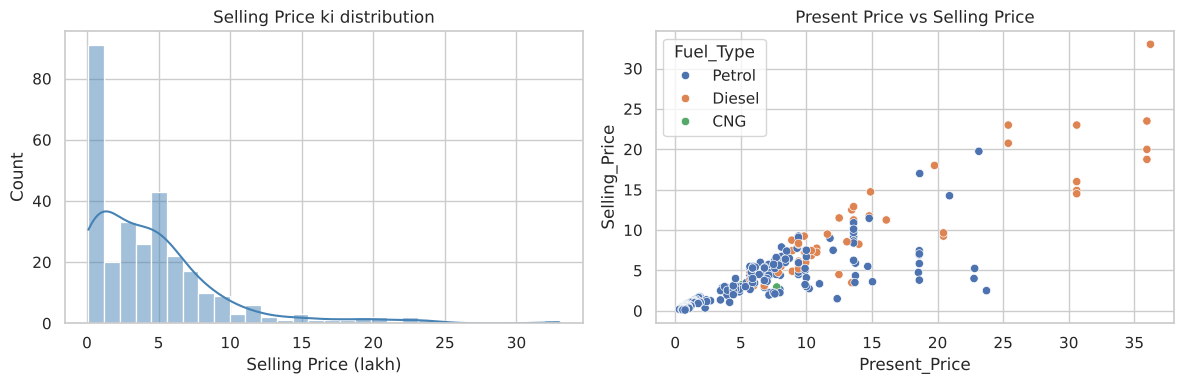

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Selling_Price"], bins=30, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Selling Price ki distribution")
ax[0].set_xlabel("Selling Price (lakh)")
sns.scatterplot(data=df, x="Present_Price", y="Selling_Price", hue="Fuel_Type", ax=ax[1])
ax[1].set_title("Present Price vs Selling Price")
plt.tight_layout(); plt.show()

**Observation:** Zyada tar gaariyan sasti hain (right-skewed). Present price aur selling price ka rishta lagbhag seedhi line jaisa hai, yani present price sab se bara factor hai.

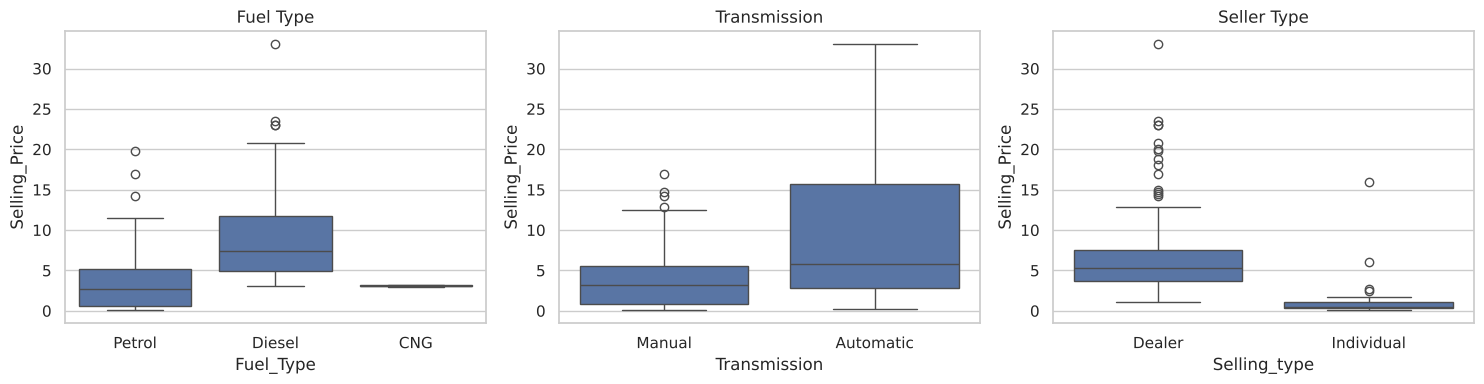

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price", ax=ax[0])
sns.boxplot(data=df, x="Transmission", y="Selling_Price", ax=ax[1])
sns.boxplot(data=df, x="Selling_type", y="Selling_Price", ax=ax[2])
ax[0].set_title("Fuel Type"); ax[1].set_title("Transmission"); ax[2].set_title("Seller Type")
plt.tight_layout(); plt.show()

**Observation:** Diesel aur Automatic gaariyan mehngi hain, aur Dealer se bikne wali gaariyon ki price Individual se zyada hai.

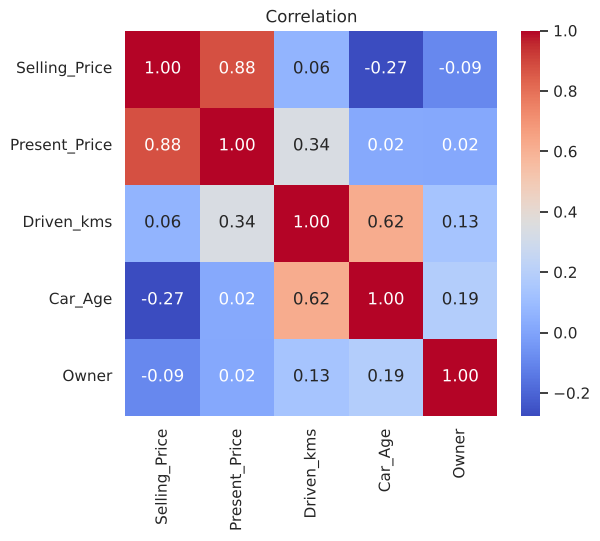

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Selling_Price", "Present_Price", "Driven_kms", "Car_Age", "Owner"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation")
plt.show()

**Observation:** `Present_Price` ka `Selling_Price` se correlation bohat zyada hai (~0.9). `Car_Age` ka negative hai (purani gaari = kam price).

## Step 6: Train / Test Split
Data ko 80% training aur 20% testing mein baant dete hain. Model training data se seekhta hai, aur testing data par check hota hai ke naye data par kaisa chalta hai.

In [8]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", Xtr.shape, " Test:", Xte.shape)

Train: (237, 8)  Test: (60, 8)


## Step 7: Models train karna
Teen regression models try karte hain: **Linear Regression**, **Random Forest**, **Gradient Boosting**.

`Selling_Price` ka **log** le kar train karte hain, kyunke price skewed hai. Prediction ke baad wapas normal price mein badal dete hain.

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
preds = {}
for name, m in models.items():
    m.fit(Xtr, np.log1p(ytr))
    p = np.expm1(m.predict(Xte))
    preds[name] = p
    results.append({
        "Model": name,
        "R2": r2_score(yte, p),
        "MAE (lakh)": mean_absolute_error(yte, p),
        "RMSE (lakh)": np.sqrt(mean_squared_error(yte, p)),
    })

results = pd.DataFrame(results).set_index("Model").round(3)
results

,R2,MAE (lakh),RMSE (lakh)
Model,,,
Linear Regression,0.860,1.050,2.057
Random Forest,0.893,0.823,1.802
Gradient Boosting,0.912,0.807,1.633


## Step 8: Model Evaluation
- **R2:** 1 ke jitna qareeb, utna acha (model price ke kitne hisse ko samajhta hai).
- **MAE:** average galti lakh rupay mein.
- **RMSE:** MAE jaisa, lekin bari galtiyon ko zyada saza deta hai.

Sirf ek split par bharosa nahi karte. **5-fold Cross Validation** se check karte hain ke result stable hai.

In [10]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv = []
for name, m in models.items():
    p = np.expm1(cross_val_predict(m, X, np.log1p(y), cv=kf))
    cv.append({"Model": name, "CV R2": r2_score(y, p), "CV MAE (lakh)": mean_absolute_error(y, p)})
cv = pd.DataFrame(cv).set_index("Model").round(3)
cv

,CV R2,CV MAE (lakh)
Model,,
Linear Regression,0.821,0.968
Random Forest,0.938,0.604
Gradient Boosting,0.944,0.577


**Natija:** Gradient Boosting sab se acha hai (R2 ~0.91 test par, ~0.94 cross validation mein). Linear Regression kamzor hai kyunke price aur features ka rishta bilkul seedha nahi hota.

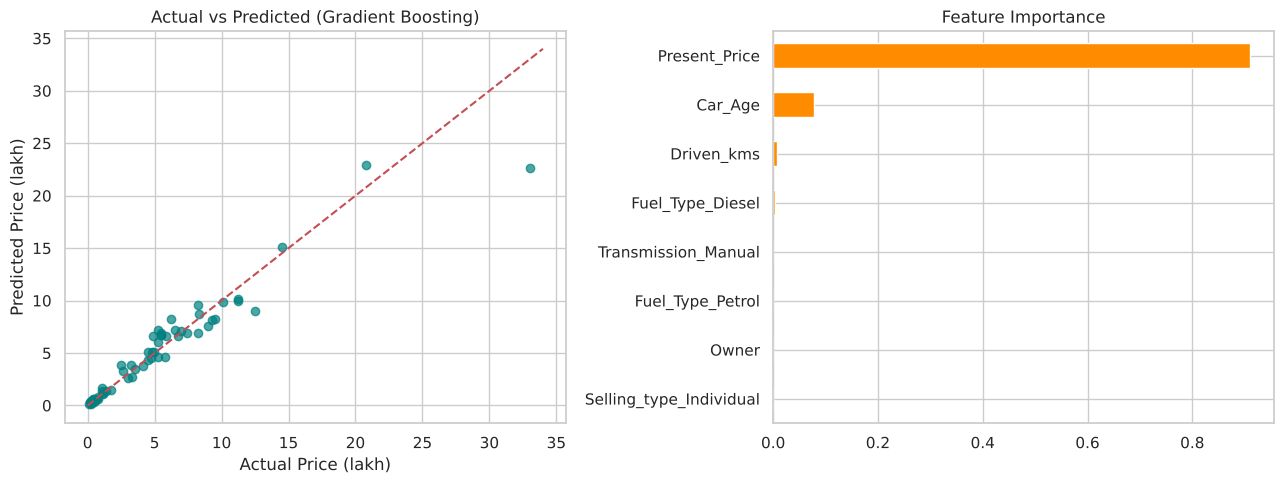

In [11]:
best = "Gradient Boosting"
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(yte, preds[best], alpha=0.7, color="teal")
lim = [0, max(yte.max(), preds[best].max()) + 1]
ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("Actual Price (lakh)"); ax[0].set_ylabel("Predicted Price (lakh)")
ax[0].set_title("Actual vs Predicted (Gradient Boosting)")

gb = models[best]
imp = pd.Series(gb.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=ax[1], color="darkorange")
ax[1].set_title("Feature Importance")
plt.tight_layout(); plt.show()

**Observation:** Points red line ke qareeb hain, yani predictions kaafi sahi hain. Sab se zaroori feature `Present_Price` hai, phir `Car_Age`, aur `Driven_kms` ka asar bohat kam hai.

## Step 9: Brand Goodwill (extra feature engineering)
Task mein *brand goodwill* ka zikar hai. Hum har brand ka **average resale ratio** (Selling Price / Present Price) nikalte hain. Jis brand ki gaari apni qeemat zyada rakhti hai, uska goodwill zyada.

Data leakage se bachne ke liye ye ratio **sirf training data** se nikalte hain.

In [12]:
df["Ratio"] = df["Selling_Price"] / df["Present_Price"]
tr = df.loc[Xtr.index]
gm = tr["Ratio"].mean()
brand_gw = tr.groupby("Brand")["Ratio"].mean()

# training rows ke liye apni row ko nikal kar average (leave-one-out)
cnt = tr.groupby("Brand")["Ratio"].transform("count")
tot = tr.groupby("Brand")["Ratio"].transform("sum")
loo = ((tot - tr["Ratio"]) / (cnt - 1)).where(cnt > 1, gm)

Xtr2, Xte2 = Xtr.copy(), Xte.copy()
Xtr2["Brand_Goodwill"] = loo
Xte2["Brand_Goodwill"] = df.loc[Xte.index, "Brand"].map(brand_gw).fillna(gm)

m2 = GradientBoostingRegressor(random_state=42).fit(Xtr2, np.log1p(ytr))
p2 = np.expm1(m2.predict(Xte2))
print("Without Brand Goodwill -> R2:", round(r2_score(yte, preds[best]), 3), " MAE:", round(mean_absolute_error(yte, preds[best]), 3))
print("With    Brand Goodwill -> R2:", round(r2_score(yte, p2), 3), " MAE:", round(mean_absolute_error(yte, p2), 3))

Without Brand Goodwill -> R2: 0.912  MAE: 0.807
With    Brand Goodwill -> R2: 0.913  MAE: 0.817


**Natija:** Brand goodwill se improvement nahi aata, kyunke ek brand ki gaariyan bohat kam hain (zyada tar brands ki 1-3 rows) aur `Present_Price` pehle hi brand ki qeemat ka asar rakhta hai. Isliye final model mein ye feature shamil nahi kiya.

## Step 10: Naye data par prediction (real-world use)
Train kiya hua model ab kisi bhi nayi gaari ki selling price bata sakta hai.

In [13]:
new_car = pd.DataFrame([{
    "Present_Price": 9.5, "Driven_kms": 40000, "Car_Age": 8, "Owner": 0,
    "Fuel_Type": "Petrol", "Selling_type": "Dealer", "Transmission": "Manual"
}])
new_X = pd.get_dummies(new_car, dtype=int).reindex(columns=X.columns, fill_value=0)
price = np.expm1(models["Gradient Boosting"].predict(new_X))[0]
print(f"Predicted selling price: {price:.2f} lakh")

Predicted selling price: 7.09 lakh


## Step 11: Conclusion
- Car price predict karne ke liye **Gradient Boosting** sab se acha raha (R2 ~0.91 test, ~0.94 cross-validation, average galti ~0.8 lakh).
- Sab se zaroori factor **Present Price** hai, phir **Car Age**. Kilometres ka asar kam hai.
- Diesel, Automatic aur Dealer se bikne wali gaariyan mehngi bikti hain.
- **Real-world use:** used-car websites (jaise CarDekho, OLX) price suggest karne ke liye, dealers fair price tay karne ke liye, aur buyers overpricing se bachne ke liye aise models use karte hain.

**Limitations:** Data sirf ~300 gaariyon ka hai, horsepower aur mileage ke columns dataset mein nahi hain, aur bohat mehngi gaariyon (jaise Land Cruiser) ke examples kam hain, is liye unki prediction kam bharosemand hogi.